# 3.1

**Равномерный спуск.** Выберем оси $x$ вправо, $y$ вверх. Материальная точка без трения движется по гладкой неподвижной кривой под действием тяжести; $\dot y=-v$, где $v>0$ постоянно. Обозначим $u_0=\dot x(0)>0$, $x(0)=x_0$, $y(0)=y_0$. Пусть $N$ — нормальная реакция, а $y'=dy/dx$.

Из второго закона Ньютона, учитывая нормаль $(-y',1)/\sqrt{1+y'^2}$:

$$m\ddot x=-\frac{Ny'}{\sqrt{1+y'^2}},\qquad m\ddot y=-mg+\frac{N}{\sqrt{1+y'^2}}.$$

Так как $\ddot y=0$, то $N=mg\sqrt{1+y'^2}$, откуда $\ddot x=-gy'$. Учитывая $y'=\dot y/\dot x=-v/\dot x$, получаем

$$\ddot x\,\dot x=gv,\quad\frac{d}{dt}(\dot x^2)=2gv,\quad \dot x=\sqrt{u_0^2+2gvt}.$$

Интегрирование и исключение времени дают

$$x=x_0+\frac{(u_0^2+2gvt)^{3/2}-u_0^3}{3gv},\qquad y=y_0-vt,$$

$$\boxed{y(x)=y_0-\frac{\left[u_0^3+3gv(x-x_0)\right]^{2/3}-u_0^2}{2g}},\qquad x\ge x_0.$$

Проверка: $\dot y=-v=\mathrm{const}$, хотя горизонтальная скорость растёт. Графики ниже показывают разные начальные горизонтальные скорости; в анимации предусмотрены воспроизведение и пауза.

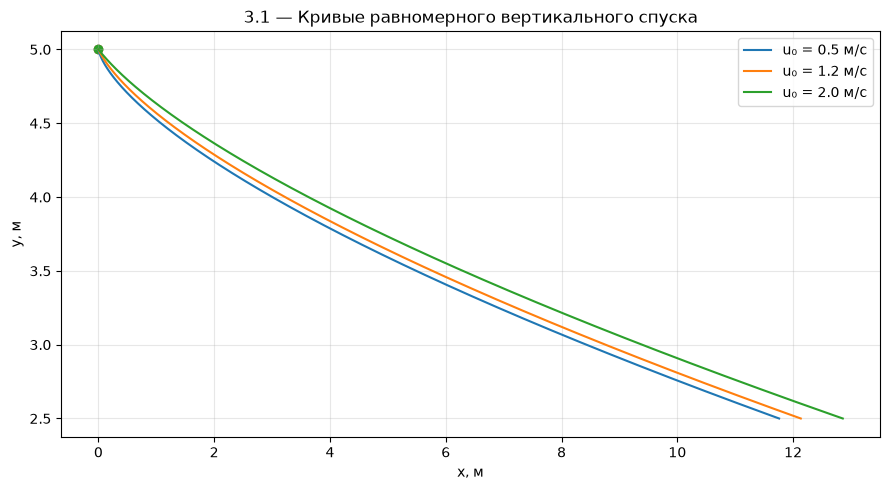

In [ ]:
# 3.1
import numpy as np
import matplotlib.pyplot as plt

g, v, x0, y0 = 9.81, 1.0, 0.0, 5.0
t = np.linspace(0, 2.5, 500)
u_values = [0.5, 1.2, 2.0]

fig, ax = plt.subplots(figsize=(9, 5))
for u0 in u_values:
    x = x0 + ((u0**2 + 2*g*v*t)**1.5 - u0**3)/(3*g*v)
    y = y0-v*t
    ax.plot(x, y, label=f"u₀ = {u0} м/с")
    ax.scatter([x0], [y0], s=35)
ax.set(xlabel="x, м", ylabel="y, м", title="3.1 — Кривые равномерного вертикального спуска")
ax.legend()
ax.grid(True, alpha=.3)
fig.tight_layout()
fig.savefig("3_1.png", dpi=170)
plt.show()

In [2]:
# 3.1
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

g, v, u0, y0, duration = 9.81, 1.0, 1.2, 5.0, 2.5
t = np.linspace(0, duration, 64)
x = ((u0**2+2*g*v*t)**1.5-u0**3)/(3*g*v)
y = y0-v*t
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(x, y, lw=2)
ax.scatter([0], [y0], color="black", s=30)
trail, = ax.plot([], [], lw=3)
ball, = ax.plot([], [], "o", markersize=10)
status = ax.text(.02, .05, "", transform=ax.transAxes, bbox={"facecolor":"white", "alpha":.85})
ax.set(xlim=(-.5, x[-1]+.7), ylim=(y[-1]-.5,y0+.7), xlabel="x, м", ylabel="y, м", title="3.1 — Равномерный вертикальный спуск")
ax.grid(True, alpha=.3)
def update(frame):
    trail.set_data(x[:frame+1],y[:frame+1])
    ball.set_data([x[frame]], [y[frame]])
    status.set_text(f"t = {t[frame]:.2f} c  |  vᵧ = {-v:.2f} м/с  |  vₓ = {np.sqrt(u0*u0+2*g*v*t[frame]):.2f} м/с")
    return trail, ball, status
ani = FuncAnimation(fig, update, frames=len(t), interval=50, blit=True)
plt.close(fig)
display(HTML(ani.to_jshtml(fps=25)))

# 3.2

**Бильярд в прямоугольнике.** Пусть размеры стола $a\times b$, положение $(x,y)$, скорость $(v_x,v_y)$ постоянна между отражениями. На вертикальной стенке $v_x\mapsto-v_x$, на горизонтальной — $v_y\mapsto-v_y$ (упругие отражения). Гамильтониан свободного движения

$$H=\frac{p_x^2+p_y^2}{2m},\qquad \dot x=p_x/m,\quad \dot y=p_y/m,\quad \dot p_x=\dot p_y=0.$$

Метод развёртки заменяет отражения прямолинейным движением через зеркально отражённые прямоугольники. Для любого действительного $s$ определим $F_L(s)=L-|\,(s\bmod 2L)-L\,|$. Тогда

$$\boxed{x(t)=F_a(x_0+v_xt),\qquad y(t)=F_b(y_0+v_yt)}.$$

После отождествления противоположных сторон развёрнутого прямоугольника $[0,2a)\times[0,2b)$ получаем прямолинейный поток на **плоском торе**. Траектория периодична, если $(v_x/a)/(v_y/b)\in\mathbb Q$ (для ненулевых компонент скорости); при иррациональном отношении она плотна на торе. В случае прямоугольника это означает плотное заполнение конфигурационной области в пределе длительного движения. Примеры ниже демонстрируют обе ситуации.

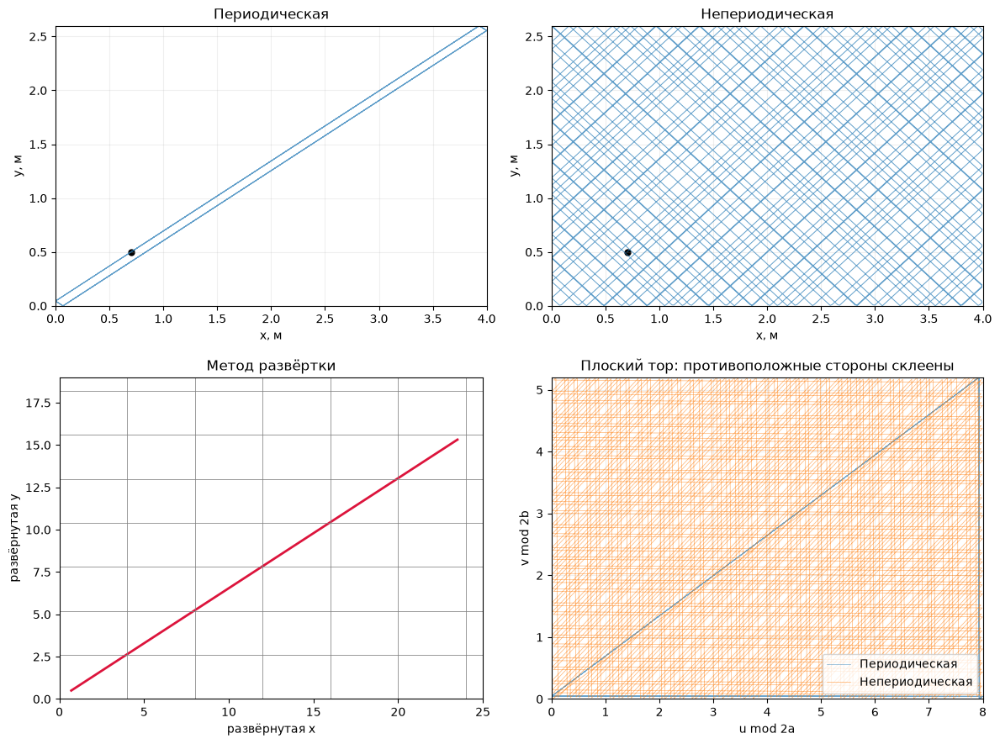

In [3]:
# 3.2
import numpy as np
import matplotlib.pyplot as plt

a, b, x0, y0 = 4.0, 2.6, 0.7, 0.5
vx = 1.2
cases = [("Периодическая", b*vx/a), ("Непериодическая", b*vx/a*np.sqrt(2))]
def fold(s, L):
    return L-np.abs(np.mod(s,2*L)-L)
fig, axes = plt.subplots(2,2,figsize=(12,9))
for j,(title,vy) in enumerate(cases):
    t = np.linspace(0, 180 if j else 26, 12000)
    xx=fold(x0+vx*t,a)
    yy=fold(y0+vy*t,b)
    ax=axes[0,j]
    ax.plot(xx,yy,lw=.7,alpha=.7)
    ax.scatter([x0],[y0],color="black",s=25)
    ax.set(xlim=(0,a),ylim=(0,b),xlabel="x, м",ylabel="y, м",title=title)
    ax.set_aspect('equal')
    ax.grid(alpha=.2)
t=np.linspace(0,19,1500)
ax=axes[1,0]
ax.plot(x0+vx*t,y0+cases[0][1]*t,color="crimson",lw=2)
for gx in np.arange(0,26,a): ax.axvline(gx,color="gray",lw=.55)
for gy in np.arange(0,21,b): ax.axhline(gy,color="gray",lw=.55)
ax.set(xlim=(0,25),ylim=(0,19),xlabel="развёрнутая x",ylabel="развёрнутая y",title="Метод развёртки")
ax.set_aspect('equal')
ax=axes[1,1]
for title,vy in cases:
    t=np.linspace(0,75 if title.startswith('Период') else 400,12000)
    ax.plot(np.mod(x0+vx*t,2*a),np.mod(y0+vy*t,2*b),lw=.45,alpha=.65,label=title)
ax.set(xlim=(0,2*a),ylim=(0,2*b),xlabel="u mod 2a",ylabel="v mod 2b",title="Плоский тор: противоположные стороны склеены")
ax.legend()
ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig("3_2.png",dpi=170)
plt.show()

In [4]:
# 3.2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

a,b,x0,y0,vx=4.0,2.6,.7,.5,1.2
cases=[("Периодическая",b*vx/a),("Иррациональная",b*vx/a*np.sqrt(2))]
t=np.linspace(0,40,64)
def fold(s,L):
    return L-np.abs(np.mod(s,2*L)-L)
fig,axes=plt.subplots(2,2,figsize=(11,6.2))
objects=[]
for j,(name,vy) in enumerate(cases):
    left=axes[j,0]
    right=axes[j,1]
    x=fold(x0+vx*t,a)
    y=fold(y0+vy*t,b)
    u=np.mod(x0+vx*t,2*a)
    w=np.mod(y0+vy*t,2*b)
    left.set(xlim=(0,a),ylim=(0,b),title=f"Стол: {name}",xlabel="x",ylabel="y")
    right.set(xlim=(0,2*a),ylim=(0,2*b),title=f"Плоский тор: {name}",xlabel="u mod 2a",ylabel="v mod 2b")
    for ax in (left,right): ax.grid(alpha=.25)
    trail,=left.plot([],[],lw=1.5)
    ball,=left.plot([],[],"o",markersize=9)
    point,=right.plot([],[],"o",markersize=8)
    objects.append((x,y,u,w,trail,ball,point))
clock=fig.suptitle("")
def update(frame):
    for x,y,u,w,trail,ball,point in objects:
        trail.set_data(x[:frame+1],y[:frame+1])
        ball.set_data([x[frame]],[y[frame]])
        point.set_data([u[frame]],[w[frame]])
    clock.set_text(f"3.2 — t={t[frame]:.1f} с | скорость сохраняется по модулю")
    return tuple(it for ob in objects for it in ob[-3:])+(clock,)
fig.tight_layout()
ani=FuncAnimation(fig,update,frames=len(t),interval=65,blit=True)
plt.close(fig)
display(HTML(ani.to_jshtml(fps=25)))

# 3.3

**Цепная линия.** Для однородной гибкой нерастяжимой цепи с линейной плотностью $\mu$ в поле тяжести обозначим горизонтальную компоненту натяжения $H>0$; она постоянна. Вертикальная компонента натяжения участка от нижней точки до координаты $x$ равна $\mu g\,s(x)$, где $s$ — длина дуги. Поэтому

$$Hy'=\mu g s,\qquad \frac{ds}{dx}=\sqrt{1+y'^2},\qquad y''=\frac{\mu g}{H}\sqrt{1+y'^2}.$$

Положим $a=H/(\mu g)$. Разделяя переменные, получаем

$$\frac{dy'}{\sqrt{1+y'^2}}=\frac{dx}{a},\quad \operatorname{arsinh}y'=\frac{x-x_c}{a},\quad y'=\sinh\frac{x-x_c}{a}.$$

Следовательно,

$$\boxed{y(x)=a\cosh\!\left(\frac{x-x_c}{a}\right)+y_c}.$$

При опорах на $x=\pm L/2$ и уровне $y=0$ имеем $y_c=-a\cosh(L/2a)$, так что $y=a[\cosh(x/a)-\cosh(L/2a)]$. Большое $a$ соответствует большему отношению $H/\mu g$ и меньшему провисанию. **При фиксированных опорах и неизменной длине одной нерастяжимой цепи значение $a$ не меняется произвольно**: ниже сравниваются разные цепи (с разными длинами/натяжениями).

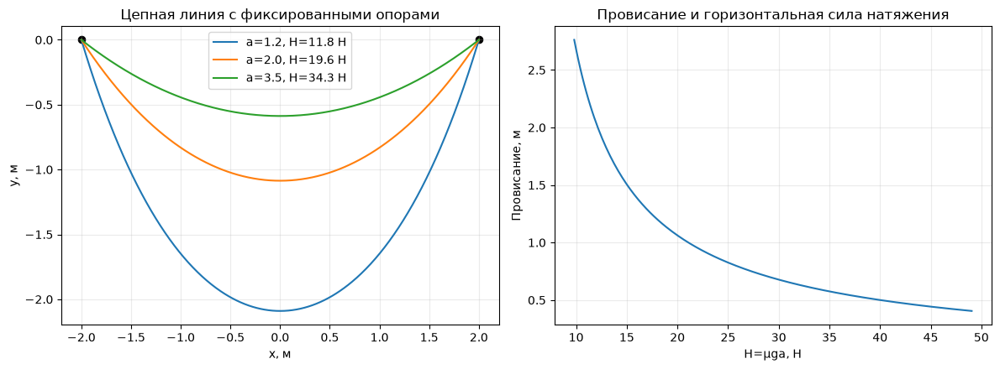

In [5]:
# 3.3
import numpy as np
import matplotlib.pyplot as plt

L,g,mu=4.0,9.81,1.0
x=np.linspace(-L/2,L/2,600)
a_values=[1.2,2.0,3.5]
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for a in a_values:
    y=a*(np.cosh(x/a)-np.cosh(L/(2*a)))
    axes[0].plot(x,y,label=f"a={a}, H={mu*g*a:.1f} Н")
axes[0].scatter([-L/2,L/2],[0,0],color="black",s=35)
axes[0].set(xlabel="x, м",ylabel="y, м",title="Цепная линия с фиксированными опорами")
axes[0].grid(alpha=.25)
axes[0].legend()
a=np.linspace(1.0,5.0,200)
sag=a*(np.cosh(L/(2*a))-1)
axes[1].plot(mu*g*a,sag)
axes[1].set(xlabel="H=μga, Н",ylabel="Провисание, м",title="Провисание и горизонтальная сила натяжения")
axes[1].grid(alpha=.25)
fig.tight_layout()
fig.savefig("3_3.png",dpi=170)
plt.show()

In [6]:
# 3.3
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.patches import FancyArrowPatch
from IPython.display import HTML, display

L,g,mu=4.0,9.81,1.0
x=np.linspace(-L/2,L/2,350)
a_values=2.15+.85*np.cos(np.linspace(0,2*np.pi,64))
fig,ax=plt.subplots(figsize=(8,5))
line,=ax.plot([],[],lw=3)
ax.scatter([-L/2,L/2],[0,0],color="black",s=45)
T=FancyArrowPatch((0,0),(.5,.5),arrowstyle="-|>",mutation_scale=14,color="tab:blue",lw=2)
W=FancyArrowPatch((0,0),(0,-.5),arrowstyle="-|>",mutation_scale=14,color="tab:red",lw=2)
ax.add_patch(T)
ax.add_patch(W)
status=ax.text(.03,.06,"",transform=ax.transAxes,bbox={"facecolor":"white","alpha":.85})
ax.set(xlim=(-2.6,2.6),ylim=(-3.1,1),xlabel="x, м",ylabel="y, м",title="3.3 — Изменение семейства цепных линий")
ax.grid(alpha=.25)
def update(frame):
    a=a_values[frame]
    y=a*(np.cosh(x/a)-np.cosh(L/(2*a)))
    line.set_data(x,y)
    q=.55
    yq=a*(np.cosh(q/a)-np.cosh(L/(2*a)))
    T.set_positions((q,yq),(q+.62,yq+.62*np.sinh(q/a)))
    W.set_positions((q,yq),(q,yq-.55))
    status.set_text(f"a = {a:.2f} м | H = {mu*g*a:.1f} Н | провисание = {a*(np.cosh(L/(2*a))-1):.2f} м\nСиняя стрелка: натяжение | красная: тяжесть")
    return line,T,W,status
ani=FuncAnimation(fig,update,frames=len(a_values),interval=60,blit=True)
plt.close(fig)
display(HTML(ani.to_jshtml(fps=25)))

# 3.4

**Таутохрона — перевёрнутая циклоида.** Материальная точка без трения отпускается из состояния покоя с произвольной высоты и достигает дна за одинаковое время. Обозначим через $s$ длину дуги, отсчитываемую от нижней точки (со знаком стороны), а через $y$ высоту над дном. Из закона сохранения энергии скорость по дуге при старте с высоты $h$ равна $|\dot s|=\sqrt{2g(h-y)}$. Время спуска поэтому удовлетворяет интегральному уравнению Абеля:

$$T(h)=\frac1{\sqrt{2g}}\int_0^h \frac{ds/dy}{\sqrt{h-y}}\,dy.$$

При $T(h)\equiv T_0$ обращение Абеля даёт

$$\frac{ds}{dy}=\frac{\sqrt{2g}\,T_0}{\pi\sqrt y},\qquad s=\frac{2\sqrt{2g}\,T_0}{\pi}\sqrt y.$$

Положим $a=gT_0^2/\pi^2$. Тогда $y=s^2/(8a)$ — уравнение перевёрнутой циклоиды. Её удобная параметризация при $-\pi\le\theta\le\pi$:

$$\boxed{x=a(\theta+\sin\theta),\qquad y=a(1-\cos\theta)},\qquad s=4a\sin(\theta/2).$$

Из $y=s^2/(8a)$ и второго закона Ньютона вдоль дуги получаем

$$\ddot s=-g\frac{dy}{ds}=-\frac{g}{4a}s,\qquad s(t)=s_0\cos\!\left(\sqrt{\frac g{4a}}\,t\right),$$

$$\boxed{T_0=\pi\sqrt{a/g}}.$$

Это время не зависит от точки старта $s_0$. Геометрически циклоида также возникает как траектория точки на окружности, катящейся без скольжения под горизонтальной направляющей.

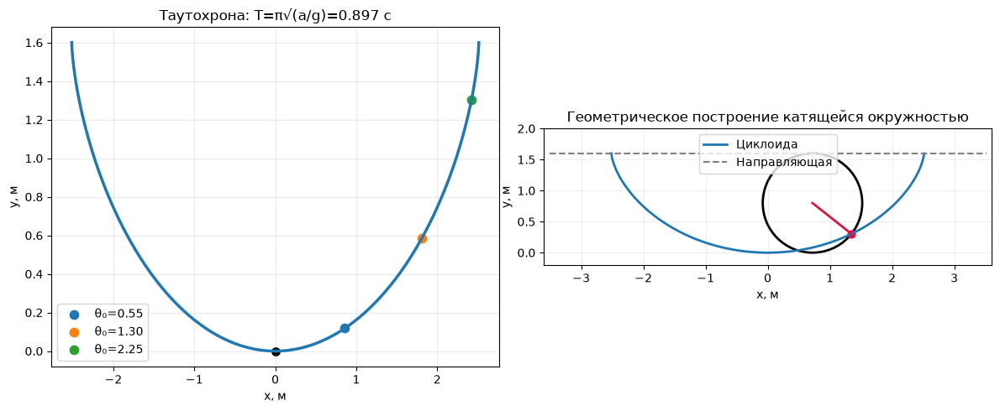

In [7]:
# 3.4
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

a,g=.8,9.81
th=np.linspace(-np.pi,np.pi,1000)
x=a*(th+np.sin(th))
y=a*(1-np.cos(th))
initial=np.array([.55,1.3,2.25])
fig,axes=plt.subplots(1,2,figsize=(12,5))
axes[0].plot(x,y,lw=2.5)
for z in initial:
    axes[0].scatter([a*(z+np.sin(z))],[a*(1-np.cos(z))],s=55,label=f"θ₀={z:.2f}")
axes[0].scatter([0],[0],color="black",s=45)
axes[0].set(xlabel="x, м",ylabel="y, м",title=f"Таутохрона: T=π√(a/g)={np.pi*np.sqrt(a/g):.3f} c")
axes[0].legend()
axes[0].grid(alpha=.25)
rr=.9
center=(a*rr,a)
axes[1].plot(x,y,lw=2,label="Циклоида")
axes[1].plot([-np.pi*a-1,np.pi*a+1],[2*a,2*a],"--",color="gray",label="Направляющая")
axes[1].add_patch(Circle(center,a,fill=False,lw=2))
axes[1].plot([center[0],a*(rr+np.sin(rr))],[center[1],a*(1-np.cos(rr))],color="crimson",lw=2)
axes[1].scatter([a*(rr+np.sin(rr))],[a*(1-np.cos(rr))],color="crimson",s=40)
axes[1].set(xlim=(-3.6,3.6),ylim=(-.2,2.0),xlabel="x, м",ylabel="y, м",title="Геометрическое построение катящейся окружностью")
axes[1].set_aspect('equal')
axes[1].legend()
axes[1].grid(alpha=.2)
fig.tight_layout()
fig.savefig("3_4.png",dpi=170)
plt.show()

In [8]:
# 3.4
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

a,g=.8,9.81
T=np.pi*np.sqrt(a/g)
t=np.linspace(0,T,64)
th=np.linspace(-np.pi,np.pi,700)
x=a*(th+np.sin(th))
y=a*(1-np.cos(th))
starts=np.array([.55,1.3,2.25])
s0=4*a*np.sin(starts/2)
fig,axes=plt.subplots(1,2,figsize=(11,4.6))
ax=axes[0]
ax.plot(x,y,color="black",lw=2)
balls=[ax.plot([],[],"o",markersize=11)[0] for _ in starts]
ax.set(xlim=(-.2,3),ylim=(-.2,1.9),xlabel="x, м",ylabel="y, м",title="Одновременный спуск с разных высот")
ax.grid(alpha=.2)
ax=axes[1]
ax.plot(x,y,color="gray",alpha=.35,lw=1)
ax.plot([-3.5,3.5],[2*a,2*a],"--",color="gray")
wheel=Circle((0,a),a,fill=False,color="tab:blue",lw=2)
ax.add_patch(wheel)
spoke,=ax.plot([],[],color="tab:blue",lw=2)
trace,=ax.plot([],[],color="crimson",lw=2)
point,=ax.plot([],[],"o",color="crimson",markersize=7)
ax.set(xlim=(-3.6,3.6),ylim=(-.2,2),xlabel="x, м",ylabel="y, м",title="Построение циклоиды катящейся окружностью")
ax.set_aspect('equal')
ax.grid(alpha=.2)
status=fig.suptitle("")
def update(frame):
    tt=t[frame]
    s=s0*np.cos(np.sqrt(g/(4*a))*tt)
    theta=2*np.arcsin(np.clip(s/(4*a),-1,1))
    for ball,z in zip(balls,theta):
        ball.set_data([a*(z+np.sin(z))],[a*(1-np.cos(z))])
    q=-np.pi+2*np.pi*frame/(len(t)-1)
    xc=a*q
    xp=a*(q+np.sin(q))
    yp=a*(1-np.cos(q))
    wheel.center=(xc,a)
    spoke.set_data([xc,xp],[a,yp])
    point.set_data([xp],[yp])
    subset=th[th<=q]
    trace.set_data(a*(subset+np.sin(subset)),a*(1-np.cos(subset)))
    status.set_text(f"3.4 — t={tt:.3f} с / общее время до дна T={T:.3f} с")
    return tuple(balls)+(wheel,spoke,trace,point,status)
fig.tight_layout()
ani=FuncAnimation(fig,update,frames=len(t),interval=65,blit=True)
plt.close(fig)
display(HTML(ani.to_jshtml(fps=25)))

# 3.5

**Математический маятник.** Масса $m$ на невесомом стержне длины $L$ отклоняется на угол $\theta$ от вертикали. Проекция второго закона Ньютона на касательное направление даёт

$$mL\ddot\theta=-mg\sin\theta,\qquad\boxed{\ddot\theta+\frac gL\sin\theta=0}.$$

При малых углах $\sin\theta\approx\theta$, поэтому $\ddot\theta+\omega_0^2\theta=0$, $\omega_0=\sqrt{g/L}$ и

$$\theta(t)=\theta(0)\cos(\omega_0t)+\frac{\dot\theta(0)}{\omega_0}\sin(\omega_0t),\quad T_{\mathrm{мал}}=2\pi\sqrt{L/g}.$$

В полной нелинейной модели сохраняется энергия

$$E=\tfrac12mL^2\dot\theta^2+mgL(1-\cos\theta).$$

Если маятник отпущен из положения $\theta_0$ без начальной скорости, то закон сохранения энергии даёт для времени четверти периода

$$\frac T4=\sqrt{\frac L{2g}}\int_0^{\theta_0}\frac{d\theta}{\sqrt{\cos\theta-\cos\theta_0}}.$$

Замена $k=\sin(\theta_0/2)$ приводит к **полному эллиптическому интегралу первого рода** $K$:

$$\boxed{T(\theta_0)=4\sqrt{\frac Lg}\,K\!\left(\sin^2\frac{\theta_0}2\right)}.$$

Здесь $K(m)=\int_0^{\pi/2}(1-m\sin^2u)^{-1/2}du$; параметр $m$ уже равен $k^2$. В фазовой плоскости $(\theta,\dot\theta)$ граница между колебаниями и вращениями — сепаратриса $E=2mgL$, или $\dot\theta=\pm2\sqrt{g/L}\cos(\theta/2)$ на $\theta\in[-\pi,\pi]$.

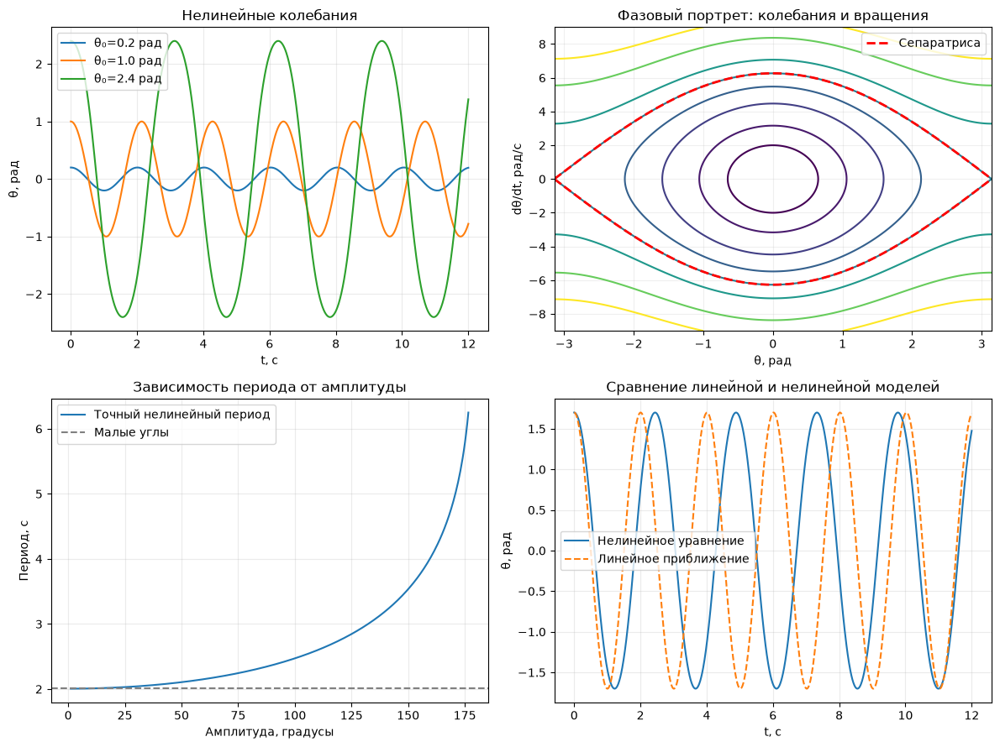

In [9]:
# 3.5
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.special import ellipk

L,g=1.0,9.81
Tmax=12.0
t=np.linspace(0,Tmax,1200)
def ode(t,z):
    return [z[1],-g/L*np.sin(z[0])]
fig,axes=plt.subplots(2,2,figsize=(12,9))
for theta0 in [.2,1.0,2.4]:
    sol=solve_ivp(ode,[0,Tmax],[theta0,0],t_eval=t,rtol=1e-9,atol=1e-11)
    axes[0,0].plot(t,sol.y[0],label=f"θ₀={theta0:.1f} рад")
axes[0,0].set(xlabel="t, с",ylabel="θ, рад",title="Нелинейные колебания")
axes[0,0].legend()
axes[0,0].grid(alpha=.25)
theta=np.linspace(-np.pi,np.pi,320)
omega=np.linspace(-9,9,320)
TH,OM=np.meshgrid(theta,omega)
energy=.5*L*L*OM**2+g*L*(1-np.cos(TH))
axes[0,1].contour(TH,OM,energy,levels=[2,5,10,15,2*g*L,25,35,45],cmap='viridis')
axes[0,1].plot(theta,2*np.sqrt(g/L)*np.cos(theta/2),"r--",lw=2,label="Сепаратриса")
axes[0,1].plot(theta,-2*np.sqrt(g/L)*np.cos(theta/2),"r--",lw=2)
axes[0,1].set(xlabel="θ, рад",ylabel="dθ/dt, рад/с",title="Фазовый портрет: колебания и вращения")
axes[0,1].legend()
axes[0,1].grid(alpha=.2)
amps=np.linspace(.02,np.pi-.06,350)
periods=4*np.sqrt(L/g)*ellipk(np.sin(amps/2)**2)
axes[1,0].plot(np.degrees(amps),periods,label="Точный нелинейный период")
axes[1,0].axhline(2*np.pi*np.sqrt(L/g),ls="--",color="gray",label="Малые углы")
axes[1,0].set(xlabel="Амплитуда, градусы",ylabel="Период, с",title="Зависимость периода от амплитуды")
axes[1,0].legend()
axes[1,0].grid(alpha=.25)
theta0=1.7
sol=solve_ivp(ode,[0,Tmax],[theta0,0],t_eval=t,rtol=1e-9,atol=1e-11)
axes[1,1].plot(t,sol.y[0],label="Нелинейное уравнение")
axes[1,1].plot(t,theta0*np.cos(np.sqrt(g/L)*t),"--",label="Линейное приближение")
axes[1,1].set(xlabel="t, с",ylabel="θ, рад",title="Сравнение линейной и нелинейной моделей")
axes[1,1].legend()
axes[1,1].grid(alpha=.25)
fig.tight_layout()
fig.savefig("3_5.png",dpi=170)
plt.show()

In [10]:
# 3.5
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

L,g=1.0,9.81
t=np.linspace(0,8,64)
def ode(t,z):
    return [z[1],-g/L*np.sin(z[0])]
small=solve_ivp(ode,[0,t[-1]],[.25,0],t_eval=t,rtol=1e-9,atol=1e-11)
large=solve_ivp(ode,[0,t[-1]],[2.2,0],t_eval=t,rtol=1e-9,atol=1e-11)
fig,axes=plt.subplots(1,2,figsize=(11,5))
ax=axes[0]
pivots=[-1.3,1.3]
rods=[ax.plot([],[],lw=2.5)[0] for _ in pivots]
bobs=[ax.plot([],[],"o",markersize=13)[0] for _ in pivots]
ax.scatter(pivots,[0,0],color="black",s=45)
ax.set(xlim=(-2.8,2.8),ylim=(-1.35,.4),title="Малые и большие колебания",xlabel="x, м",ylabel="y, м")
ax.set_aspect('equal')
ax.grid(alpha=.2)
ax=axes[1]
ax.plot(small.y[0],small.y[1],alpha=.3,label="Малые углы")
ax.plot(large.y[0],large.y[1],alpha=.3,label="Большие углы")
ax.plot([-np.pi,np.pi],[0,0],alpha=0)
ps,=ax.plot([],[],"o",markersize=8)
pl,=ax.plot([],[],"o",markersize=8)
ax.set(xlim=(-3.4,3.4),ylim=(-8,8),xlabel="θ, рад",ylabel="dθ/dt, рад/с",title="Фазовая плоскость")
ax.legend()
ax.grid(alpha=.2)
status=fig.suptitle("")
def update(frame):
    for i,sol in enumerate((small,large)):
        ang=sol.y[0,frame]
        px=pivots[i]
        bx=px+L*np.sin(ang)
        by=-L*np.cos(ang)
        rods[i].set_data([px,bx],[0,by])
        bobs[i].set_data([bx],[by])
    ps.set_data([small.y[0,frame]],[small.y[1,frame]])
    pl.set_data([large.y[0,frame]],[large.y[1,frame]])
    status.set_text(f"3.5 — t={t[frame]:.2f} с | θ мал.={small.y[0,frame]:.2f} рад | θ бол.={large.y[0,frame]:.2f} рад")
    return tuple(rods+bobs+[ps,pl,status])
fig.tight_layout()
ani=FuncAnimation(fig,update,frames=len(t),interval=65,blit=True)
plt.close(fig)
display(HTML(ani.to_jshtml(fps=25)))